# Extreme sea-level rankings

**Indicator:** the ten highest and ten lowest hourly sea levels at the tide gauge relative to MHHW, with the ENSO phase at the time of each event.

```{glue:figure} SL_rankings
:scale: 40%
:align: right
```

Ranking extremes puts new high or low water levels into the context of the whole tide-gauge record. Events are required to be more than three days apart so that one episode is not counted several times.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from myst_nb import glue

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level.py).')
sys.path.insert(0, str(repo_root / 'functions'))
import matplotlib.colors as mcolors
import seaborn as sns

from data_downloaders import download_oni_index, download_uhslc_data
from sea_level import (
    ONI_URL, build_output_filename, build_site_tag, get_top_10_table, get_uhslc_datum,
    load_site_config, resolve_eez, save_dict_json, save_table_to_csv, sea_level_config_path,
    station_series,
)
from sea_level_plotting import make_plotly_figure_rankings, make_rankings_static_figure, style_oni_based

## 1. Configuration

In [3]:
site_key = 'Palau'  # sea-level configuration written by 00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
start_date = pd.Timestamp(site_cfg['start_date'])
end_date = pd.Timestamp(site_cfg['end_date'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
eez, eez_geometry = resolve_eez(country, repo_root / site_cfg['eez_file'])

site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
matrix_dir = repo_root / 'matrix_cc' / 'figures'
for directory in (fig_dir, tab_dir, matrix_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(name, site_name, station_lon, station_lat, ext=ext)

glue('station', station, display=False)
glue('country', country, display=False)
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); analysis period {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d}')
print(f'Outputs: {fig_dir.relative_to(repo_root)} and {tab_dir.relative_to(repo_root)}')

Malakal, Palau (UHSLC 007); analysis period 1993-01-01 to 2024-12-31
Outputs: outputs/figures/palau_uhslc007_lat7p329_lon134p450 and outputs/tables/palau_uhslc007_lat7p329_lon134p450


## 2. Hourly sea level relative to MHHW (m)

The full hourly record is used (not only the trend period) so that historical extremes are included.

In [4]:
rsl = download_uhslc_data(sea_level_dir, uhslc_id, 'hourly')
mhhw, _ = get_uhslc_datum(uhslc_id, 'MHHW')
rsl['sea_level'] = (rsl['sea_level'] - mhhw) / 1000.0
rsl['sea_level'].attrs.update(units='m', datum='MHHW')
hourly = station_series(rsl).to_series()
monthly_mean = hourly.resample('MS').mean()
monthly_max = hourly.resample('MS').max()
monthly_min = hourly.resample('MS').min()
print(f'Hourly record: {hourly.first_valid_index():%Y-%m-%d} to {hourly.last_valid_index():%Y-%m-%d} '
      f'({100 * hourly.notna().mean():.0f}% of hours present).')

Hourly record: 1969-05-18 to 2026-05-31 (97% of hours present).


## 3. Top-10 table

Hourly values smooth very short peaks, so these rankings can differ slightly from rankings based on higher-frequency data. Highlighted cells indicate events during El Niño (red) or La Niña (blue).

In [5]:
oni = download_oni_index(ONI_URL)
top_10_table = get_top_10_table(rsl, oni)
max_top = top_10_table[top_10_table['type'] == 'max'].reset_index(drop=True)
min_top = top_10_table[top_10_table['type'] == 'min'].reset_index(drop=True)
top_10_display = pd.DataFrame({
    'Rank': max_top['rank'],
    'Highest': max_top['sea level (m)'].round(3),
    'Highest Date': max_top['date'].dt.strftime('%Y-%m-%d %H:%M'),
    'Highest ONI Mode': max_top['ONI Mode'],
    'Lowest': min_top['sea level (m)'].round(3),
    'Lowest Date': min_top['date'].dt.strftime('%Y-%m-%d %H:%M'),
    'Lowest ONI Mode': min_top['ONI Mode'],
    'Zone': 'UTC',
    'ONI max': max_top['ONI'],
    'ONI min': min_top['ONI'],
})
save_table_to_csv(top_10_display, tab_dir, out('SL_top_10_table', 'csv'))
save_dict_json({'station': station, 'uhslc_id': uhslc_id, 'units': 'm above MHHW',
                'records': top_10_display.to_dict(orient='records')},
               tab_dir, out('SL_top_10_table', 'json'))

norm = mcolors.Normalize(vmin=-3, vmax=3)
cmap = sns.color_palette('coolwarm', as_cmap=True)
(top_10_display.style
    .apply(lambda row: style_oni_based(row, norm, cmap), axis=1)
    .hide(subset=['Highest ONI Mode', 'Lowest ONI Mode', 'ONI max', 'ONI min'], axis=1)
    .hide()
    .format({'Highest': '{:.2f} m', 'Lowest': '{:.2f} m'})
    .set_caption(f'Top-10 hourly sea levels at {station} (m above MHHW)'))

Rank,Highest,Highest Date,Lowest,Lowest Date,Zone
1,0.70 m,2025-11-07 10:00,-2.19 m,1992-01-19 17:00,UTC
2,0.62 m,2013-06-23 22:00,-2.18 m,1986-12-31 17:00,UTC
3,0.61 m,2016-10-16 10:00,-2.17 m,1982-12-31 18:00,UTC
4,0.61 m,2021-03-29 11:00,-2.12 m,2002-12-04 17:00,UTC
5,0.59 m,2016-05-07 22:00,-2.11 m,1995-01-01 17:00,UTC
6,0.58 m,2011-09-29 11:00,-2.11 m,1970-01-08 18:00,UTC
7,0.58 m,1998-10-07 11:00,-2.10 m,1983-01-28 17:00,UTC
8,0.58 m,2021-12-05 10:00,-2.10 m,1982-12-02 18:00,UTC
9,0.58 m,2011-03-21 23:00,-2.10 m,1987-01-29 17:00,UTC
10,0.58 m,2024-10-19 11:00,-2.09 m,1991-12-22 18:00,UTC


## 4. Time series of extremes

The interactive figure shows the monthly mean and range with the ranked events; the static version below is used for printed products.

In [6]:
figly = make_plotly_figure_rankings(monthly_mean, monthly_max, monthly_min, top_10_table, station)
figly.write_html(fig_dir / out('SL_top_10_plot', 'html'), include_plotlyjs='cdn')
figly

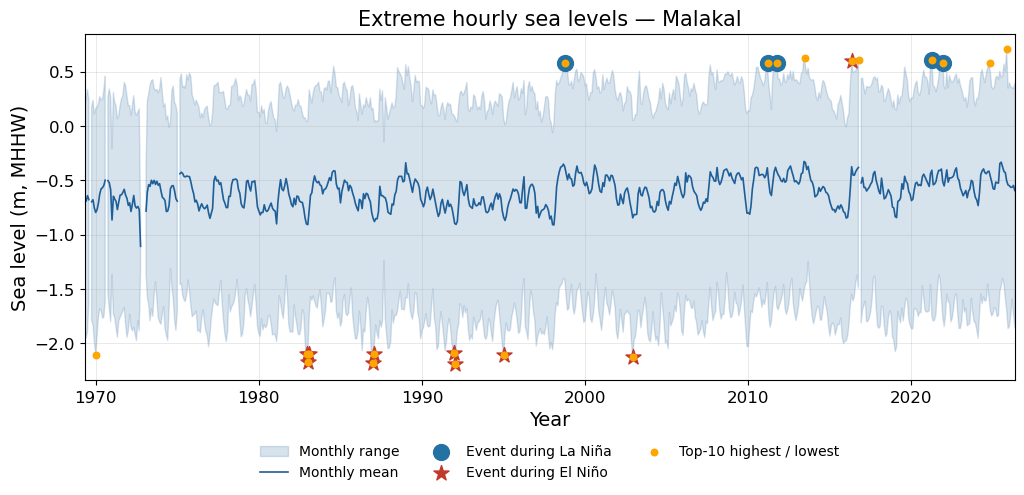

In [7]:
fig, ax = make_rankings_static_figure(monthly_mean, monthly_max, monthly_min, top_10_table, station)
glue('SL_rankings', fig, display=False)
fig.savefig(fig_dir / out('SL_rankings'), dpi=300, bbox_inches='tight')

```{glue:figure} SL_rankings
:name: "SL_rankings"

Monthly mean and range of hourly sea level at {glue:text}`station` (m above MHHW) with the ten highest and ten lowest events; stars and circles mark events during El Niño and La Niña.
```

## Interpretation and reproducibility notes

- Rankings use UHSLC Fast Delivery hourly data relative to the station MHHW; values from Research Quality data or other datums can differ by a few centimetres.
- Rankings depend on record length: a record that starts later or contains long gaps can miss historical extremes.
- The ENSO phase is the ONI-based classification of the calendar month in which the event occurred.